# Q15

(< cv2.DMatch 000001C4B5928FD0>, < cv2.DMatch 000001C4B77A2DB0>, < cv2.DMatch 000001C4B77A1B70>, < cv2.DMatch 000001C4B77A2D70>, < cv2.DMatch 000001C4B77A17B0>, < cv2.DMatch 000001C4B77A2C30>, < cv2.DMatch 000001C4B77A2D10>, < cv2.DMatch 000001C4B77A2BD0>, < cv2.DMatch 000001C4B77A2B30>, < cv2.DMatch 000001C4B77A2C10>, < cv2.DMatch 000001C4B77A2B10>, < cv2.DMatch 000001C4B77A0C30>, < cv2.DMatch 000001C4B77A2CD0>, < cv2.DMatch 000001C4B77A2CB0>, < cv2.DMatch 000001C4B77A0BB0>, < cv2.DMatch 000001C4B77A2DD0>, < cv2.DMatch 000001C4B77A2C90>, < cv2.DMatch 000001C4B77A2BB0>, < cv2.DMatch 000001C4B77A2BF0>, < cv2.DMatch 000001C4B77A2AF0>, < cv2.DMatch 000001C4B77A2D50>, < cv2.DMatch 000001C4B77A2A10>, < cv2.DMatch 000001C4B77A2A70>, < cv2.DMatch 000001C4B77A2B90>, < cv2.DMatch 000001C4B77A2D30>, < cv2.DMatch 000001C4B77A2B70>, < cv2.DMatch 000001C4B77A2DF0>, < cv2.DMatch 000001C4B77A1F90>, < cv2.DMatch 000001C4B77A2A30>, < cv2.DMatch 000001C4B77A2C50>, < cv2.DMatch 000001C4B77A2CF0>, < cv2.D

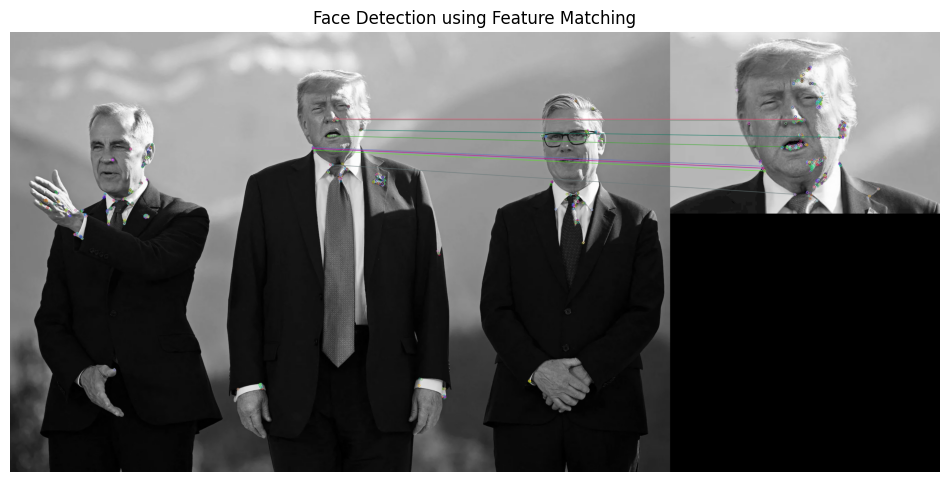

In [3]:
import cv2
import matplotlib.pyplot as plt

img1 = cv2.imread("trump-canada.webp", 0)
img2 = cv2.imread("trump2.png", 0)

orb = cv2.ORB_create()

# Detect keypoints and compute descriptors
kp1, des1 = orb.detectAndCompute(img1, None)
kp2, des2 = orb.detectAndCompute(img2, None)

bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)

matches = bf.match(des1, des2)
print(matches)
matches = sorted(matches, key=lambda x: x.distance)

# Draw best 10 matches
result = cv2.drawMatches(
    img1, kp1, img2, kp2, matches[:10], None
)

plt.figure(figsize=(12, 6))
plt.imshow(result, cmap="gray")
plt.title("Face Detection using Feature Matching")
plt.axis("off")
plt.show()

# 14)

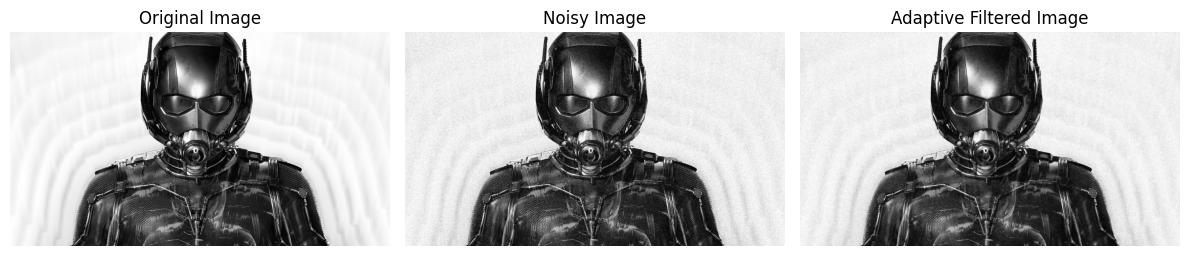

In [26]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import wiener

# Read the image
img = cv2.imread("antman.jpg", 0)

# Add Gaussian noise
noise = np.random.normal(0, 25, img.shape)
noisy = np.clip(img + noise, 0, 255).astype(np.uint8)

# Apply adaptive Wiener filter
filtered = wiener(noisy.astype(float), (5, 5))
filtered = np.clip(filtered, 0, 255).astype(np.uint8)

# Display images
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(noisy, cmap='gray')
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(filtered, cmap='gray')
plt.title("Adaptive Filtered Image")
plt.axis("off")

plt.tight_layout()
plt.show()


# 10

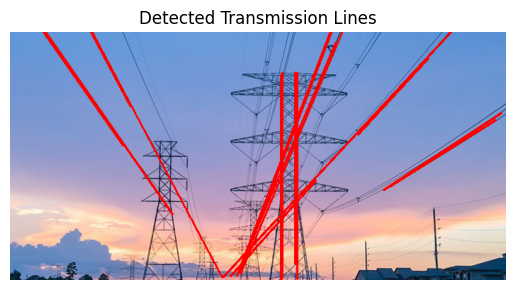

In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("transmission-line-post.jpg")

gray = cv2.imread("transmission-line-post.jpg",0)

edges = cv2.Canny(gray, 200, 300)

lines = cv2.HoughLinesP(edges, 1, np.pi/180, 130,
                        minLineLength=100, maxLineGap=40)

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line
        cv2.line(img, (int(x1), int(y1)),
                 (int(x2), int(y2)), (0, 0, 255), 2)

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Detected Transmission Lines")
plt.axis("off")
plt.show()

# 12

Original Size: 64.0 KB
DCT Size: 4.88 KB
Huffman Size: 53.44 KB
Haar LL Size: 32.0 KB


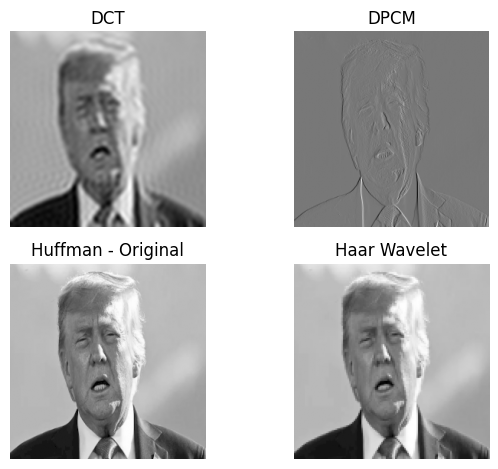

In [8]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pywt
from dahuffman import HuffmanCodec

# Read image
img = cv2.imread("trump2.png", 0)
img = cv2.resize(img, (256, 256))

# Original size
print("Original Size:", round(img.nbytes / 1024, 2), "KB")

# 1. DCT
dct = cv2.dct(np.float32(img))
dct[50:, :] = 0
dct[:, 50:] = 0
dct_img = cv2.idct(dct)
print("DCT Size:", round(50 * 50 * 2 / 1024, 2), "KB")

# 2. DPCM
dpcm = np.diff(img.astype(int), axis=1)

# 3. Huffman Coding
pixels = img.flatten()
codec = HuffmanCodec.from_data(pixels)
encoded = codec.encode(pixels)
print("Huffman Size:", round(len(encoded) / 1024, 2), "KB")

# 4. Haar Wavelet
LL, (LH, HL, HH) = pywt.dwt2(img, "haar")
print("Haar LL Size:", round(LL.size * 2 / 1024, 2), "KB")

# Display results
plt.subplot(2, 2, 1)
plt.imshow(dct_img, cmap="gray")
plt.title("DCT")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(dpcm, cmap="gray")
plt.title("DPCM")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(img, cmap="gray")
plt.title("Huffman - Original")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(LL, cmap="gray")
plt.title("Haar Wavelet")
plt.axis("off")

plt.tight_layout()
plt.show()


# 13

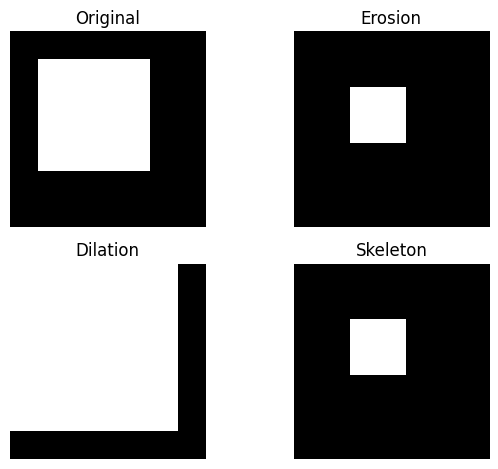

In [62]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Create a binary image
img = np.array([
    [0, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 0, 0],
    [0, 1, 1, 1, 1, 0, 0],
    [0, 1, 1, 1, 1, 0, 0],
    [0, 1, 1, 1, 1, 0, 0],
    [0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0]
], dtype=np.uint8)

img = img * 255

# Structuring element
kernel = np.ones((3, 3), np.uint8)

# Erosion and dilation
erosion = cv2.erode(img, kernel, iterations=1)
dilation = cv2.dilate(img, kernel, iterations=1)

# Skeleton extraction
skeleton = np.zeros(img.shape, np.uint8)
temp = img.copy()

while cv2.countNonZero(temp) > 0:
    eroded = cv2.erode(temp, kernel)
    opened = cv2.dilate(eroded, kernel)
    difference = cv2.subtract(temp, opened)
    skeleton = cv2.bitwise_or(skeleton, difference)
    temp = eroded

# Display results
images = [img, erosion, dilation, skeleton]
titles = ["Original", "Erosion", "Dilation", "Skeleton"]

for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()


# 11

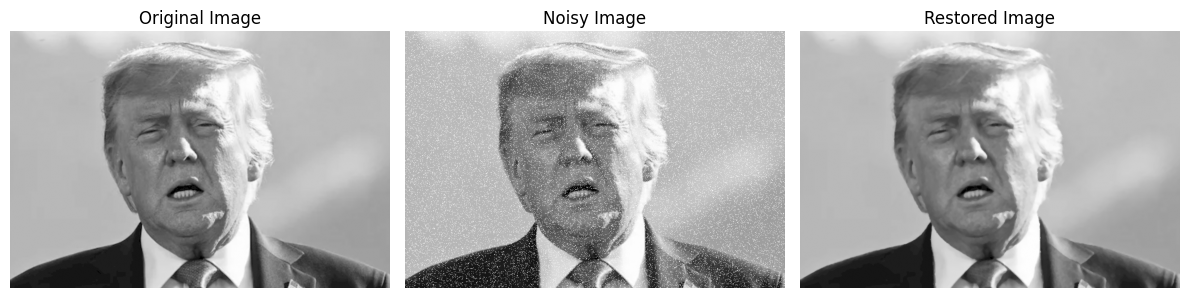

In [72]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image in grayscale
img = cv2.imread("trump2.png", 0)

# Check whether image loaded
if img is None:
    print("Image not found!")
else:
    # Add salt noise
    noise = np.random.rand(*img.shape) < 0.08
    noisy = img.copy()
    noisy[noise] = 255

    # Restore image using median filter
    restored = cv2.medianBlur(noisy, 5)

    # Display images
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(img, cmap="gray")
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(noisy, cmap="gray")
    plt.title("Noisy Image")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(restored, cmap="gray")
    plt.title("Restored Image")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


# 9th

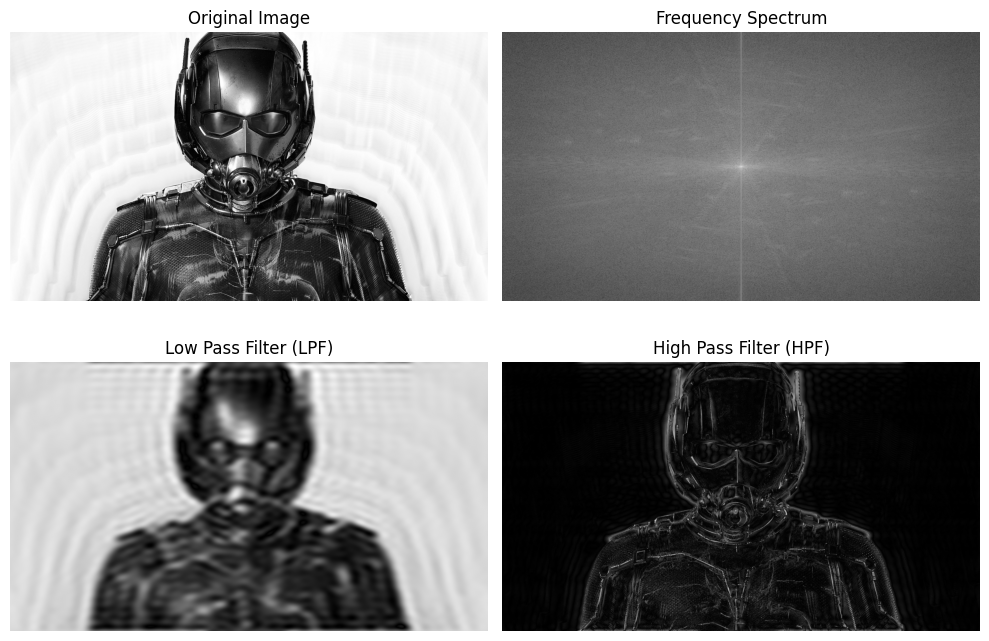

In [76]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read noisy image
img = cv2.imread("antman.jpg", 0)

# Apply Fourier Transform
f = np.fft.fft2(img)
fshift = np.fft.fftshift(f)

# Create frequency mask
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2

mask = np.zeros((rows, cols), np.uint8)
mask[crow-30:crow+30, ccol-30:ccol+30] = 1

# Low Pass Filter (LPF)
lpf = fshift * mask
img_lpf = np.abs(np.fft.ifft2(np.fft.ifftshift(lpf)))

# High Pass Filter (HPF)
hpf = fshift * (1 - mask)
img_hpf = np.abs(np.fft.ifft2(np.fft.ifftshift(hpf)))

# Display results
plt.figure(figsize=(10, 7))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(np.log1p(np.abs(fshift)), cmap="gray")
plt.title("Frequency Spectrum")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(img_lpf, cmap="gray")
plt.title("Low Pass Filter (LPF)")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(img_hpf, cmap="gray")
plt.title("High Pass Filter (HPF)")
plt.axis("off")

plt.tight_layout()
plt.show()


# 8th

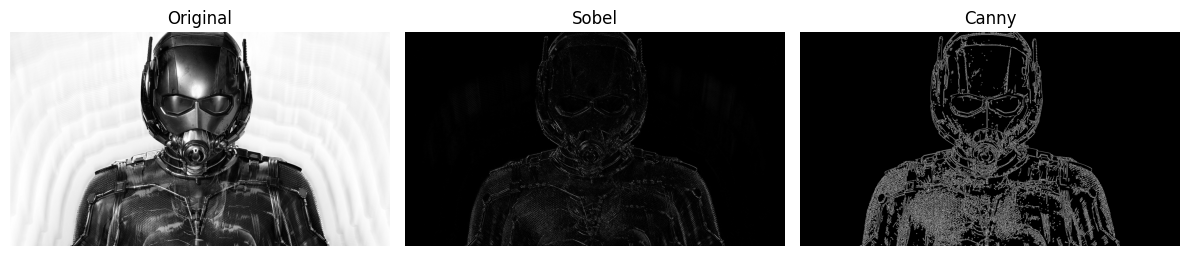

In [91]:

import cv2
import matplotlib.pyplot as plt

# Read image
img = cv2.imread("antman.jpg", 0)

# Sobel filter
sobel = cv2.Sobel(img, cv2.CV_8U, 1, 1, ksize=3)

# Canny filter
canny = cv2.Canny(img, 100,200)

# Display images
plt.figure(figsize=(12, 6))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(sobel, cmap="gray")
plt.title("Sobel")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(canny, cmap="gray")
plt.title("Canny")
plt.axis("off")

plt.tight_layout()
plt.savefig("sobel_canny.jpg")
plt.show()


# 7th

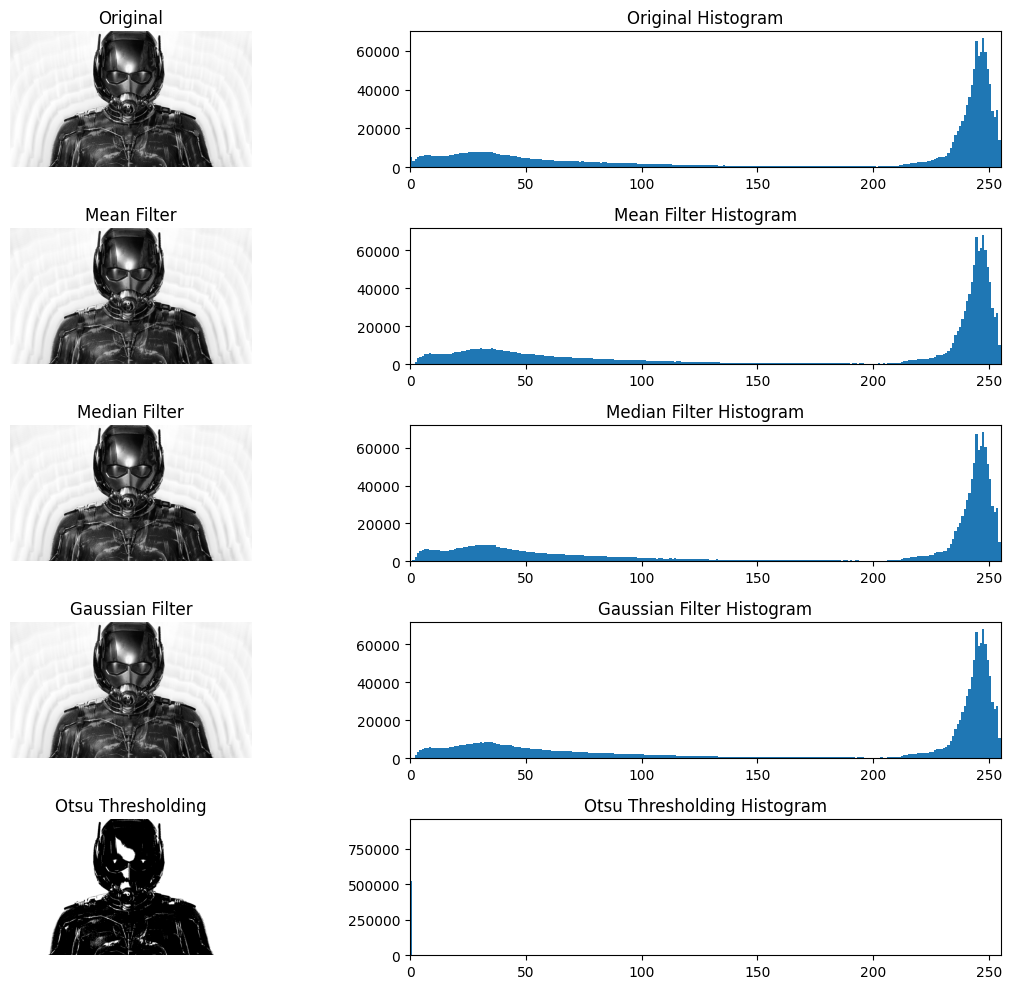

In [95]:

import cv2
import matplotlib.pyplot as plt

# Read image in grayscale
img = cv2.imread("antman.jpg", 0)

# Apply filters
mean = cv2.blur(img, (3, 3))
median = cv2.medianBlur(img, 3)
gaussian = cv2.GaussianBlur(img, (3, 3), 0)

# Otsu thresholding
_, otsu = cv2.threshold(
    img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Store images and titles
images = [img, mean, median, gaussian, otsu]
titles = ["Original", "Mean Filter", "Median Filter",
          "Gaussian Filter", "Otsu Thresholding"]

# Display images and histograms
plt.figure(figsize=(12, 10))

for i in range(5):
    plt.subplot(5, 2, 2*i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

    plt.subplot(5, 2, 2*i + 2)
    plt.hist(images[i].ravel(), bins=256, range=(0, 256))
    plt.title(titles[i] + " Histogram")
    plt.xlim(0, 255)

plt.tight_layout()
plt.show()


# 6th

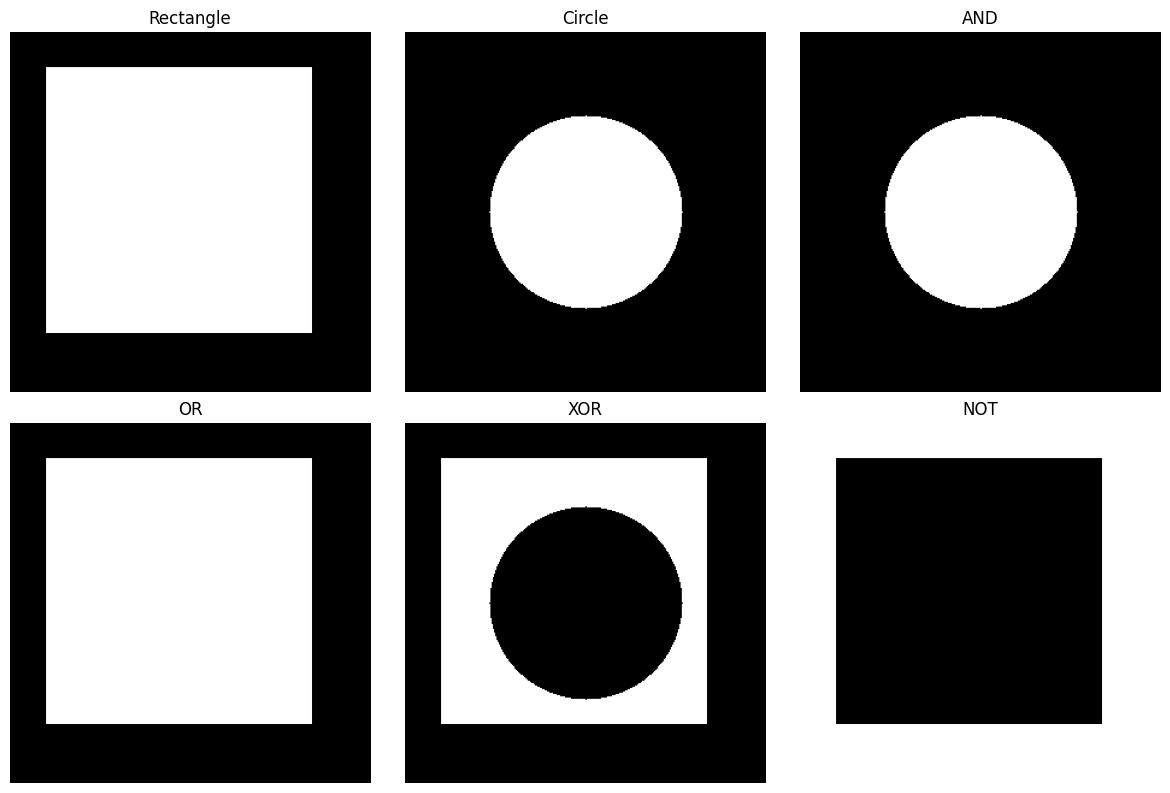

In [96]:

import matplotlib.pyplot as plt
import cv2
import numpy as np

img1 = np.zeros((300, 300), dtype="uint8")
img2 = np.zeros((300, 300), dtype="uint8")

cv2.rectangle(img1, (30, 30), (250, 250), 255, -1)
cv2.circle(img2, (150, 150), 80, 255, -1)

bit_and = cv2.bitwise_and(img1, img2)
bit_or = cv2.bitwise_or(img1, img2)
bit_xor = cv2.bitwise_xor(img1, img2)
bit_not = cv2.bitwise_not(img1)

plt.figure(figsize=(12, 8))

plt.subplot(2, 3, 1)
plt.imshow(img1, cmap="gray")
plt.title("Rectangle")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(img2, cmap="gray")
plt.title("Circle")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(bit_and, cmap="gray")
plt.title("AND")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(bit_or, cmap="gray")
plt.title("OR")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(bit_xor, cmap="gray")
plt.title("XOR")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(bit_not, cmap="gray")
plt.title("NOT")
plt.axis("off")

plt.tight_layout()
plt.show()


# 5th

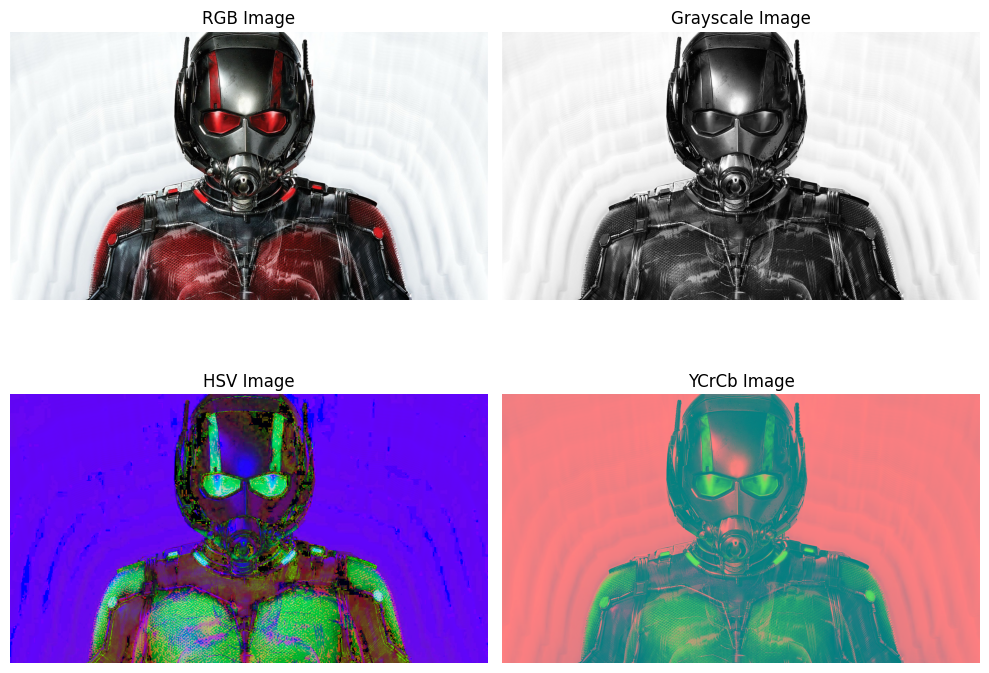

In [5]:
import cv2
import matplotlib.pyplot as plt

# Read image
img = cv2.imread("antman.jpg")

# Convert into different color models
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
ycrcb = cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb)

# Display images
plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(rgb)
plt.title("RGB Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(hsv)
plt.title("HSV Image")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(ycrcb)
plt.title("YCrCb Image")
plt.axis("off")

plt.tight_layout()
plt.show()

# 4th

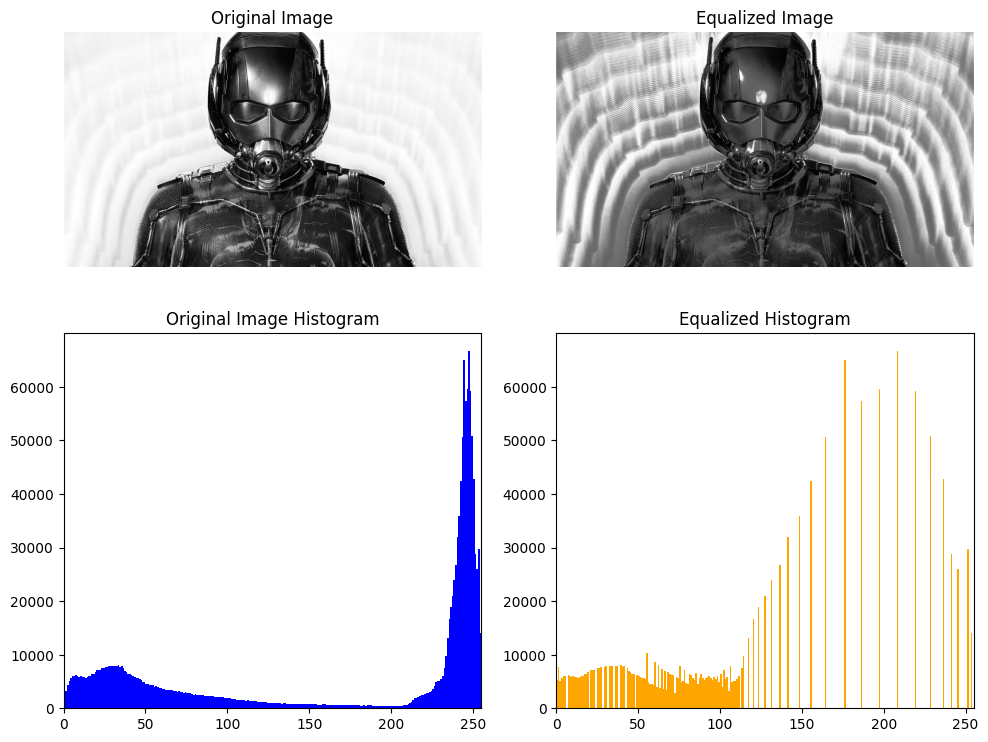

True

In [6]:
import cv2
import matplotlib.pyplot as plt

# Read image in grayscale
img = cv2.imread("antman.jpg", 0)

# Apply histogram equalization
equalized = cv2.equalizeHist(img)

# Display images
plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(equalized, cmap="gray")
plt.title("Equalized Image")
plt.axis("off")

# Original histogram
plt.subplot(2, 2, 3)
plt.hist(img.ravel(), bins=256, range=(0, 256), color="blue")
plt.title("Original Image Histogram")
plt.xlim(0, 255)

# Equalized histogram
plt.subplot(2, 2, 4)
plt.hist(equalized.ravel(), bins=256, range=(0, 256), color="orange")
plt.title("Equalized Histogram")
plt.xlim(0, 255)

plt.tight_layout()
plt.show()

# Save equalized image
cv2.imwrite("equalized_image.jpg", equalized)

# 3th

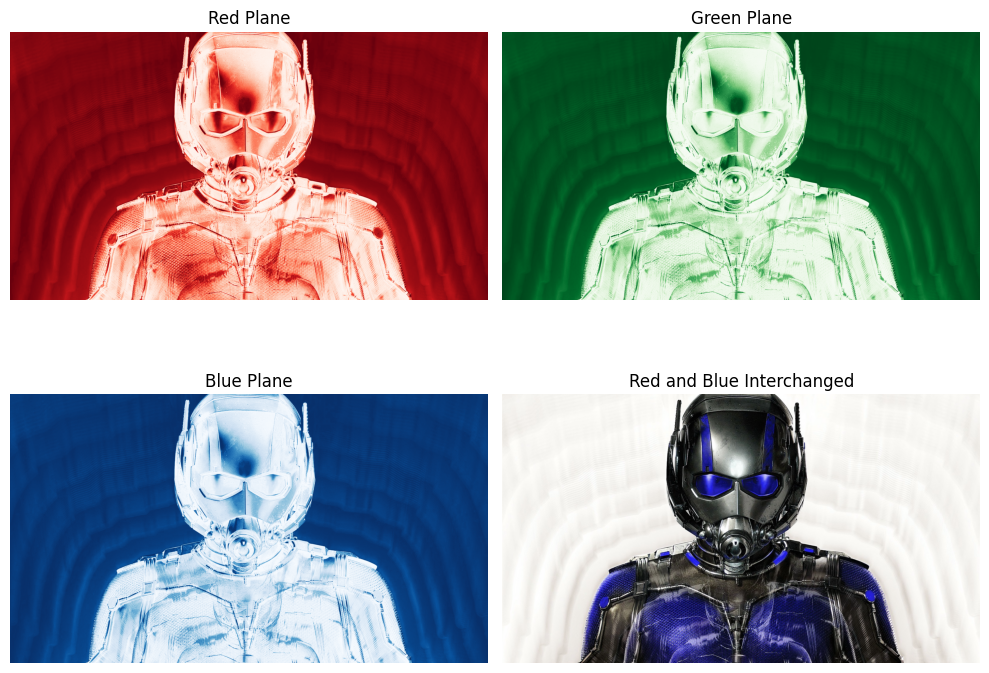

In [28]:

from PIL import Image
import matplotlib.pyplot as plt

# Read image
img = Image.open("antman.jpg")

# Split RGB channels
R, G, B = img.split()

# Interchange Red and Blue
RB = Image.merge("RGB", (B, G, R))

# Display images
plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(R, cmap="Reds")
plt.title("Red Plane")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(G, cmap="Greens")
plt.title("Green Plane")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(B, cmap="Blues")
plt.title("Blue Plane")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(RB)
plt.title("Red and Blue Interchanged")
plt.axis("off")

plt.tight_layout()
plt.savefig("RGB_channel.jpg")
plt.show()


# 2)

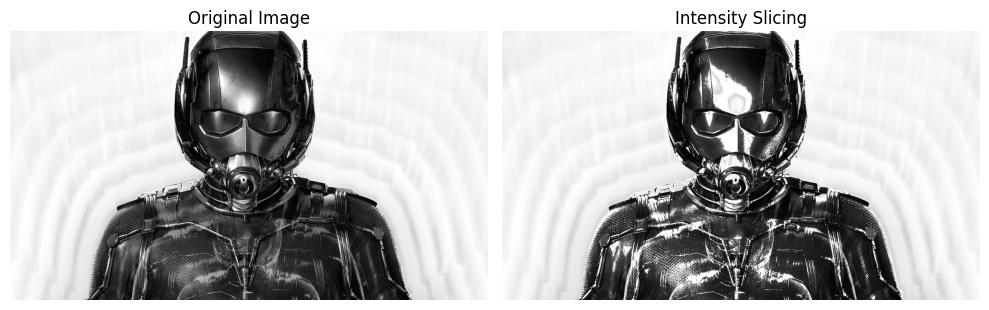

In [2]:

import cv2
import matplotlib.pyplot as plt

# Read image in grayscale
img = cv2.imread("antman.jpg", 0)

# Apply intensity slicing
sliced = img.copy()
sliced[(img >= 100) & (img <= 200)] = 255

# Display images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sliced, cmap="gray")
plt.title("Intensity Slicing")
plt.axis("off")

plt.tight_layout()
plt.show()


# 1)

In [1]:

from PIL import Image, ImageOps

# Read image
img = Image.open("antman.jpg")
img.show()

# Resize image
resizing = img.resize((61, 40))
resizing.show()

# Crop image
cropped = img.crop((200, 300, 400, 500))
cropped.show()

# Display image properties
print("Size:", img.size)
print("Width:", img.width)
print("Height:", img.height)
print("Mode:", img.mode)
print("Format:", img.format)

# Convert to grayscale
gray = img.convert("L")
gray.show()

# Convert to binary
binary = img.convert("1")
binary.show()

# Rotate image
rot = img.rotate(45)
rot.show()

# Flip image horizontally
flip = ImageOps.flip(img)
flip.show()

# Mirror image horizontally
mirror = ImageOps.mirror(img)
mirror.show()

# Invert grayscale image
neg = ImageOps.invert(gray)
neg.show()

# Display pixel values
print("RGB Pixel:", img.getpixel((20, 20)))
print("Gray Pixel:", gray.getpixel((20, 20)))
print("Binary Pixel:", binary.getpixel((20, 20)))

# Change a pixel to red
img.putpixel((20, 20), (255, 0, 0))
img.show()


Size: (1600, 900)
Width: 1600
Height: 900
Mode: RGB
Format: JPEG
RGB Pixel: (239, 243, 244)
Gray Pixel: 242
Binary Pixel: 255
